Number of hours with AQI exactly 500: 3820


C:\Users\Asus\AppData\Local\Temp\ipykernel_7304\65544116.py:23: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg = df['AQI'].resample('M').mean()
C:\Users\Asus\AppData\Local\Temp\ipykernel_7304\65544116.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df.index.month, y=df['AQI'], ax=axes[2], palette="Blues")
C:\Users\Asus\AppData\Local\Temp\ipykernel_7304\65544116.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df.index.hour, y=df['AQI'], ax=axes[3], palette="Oranges")


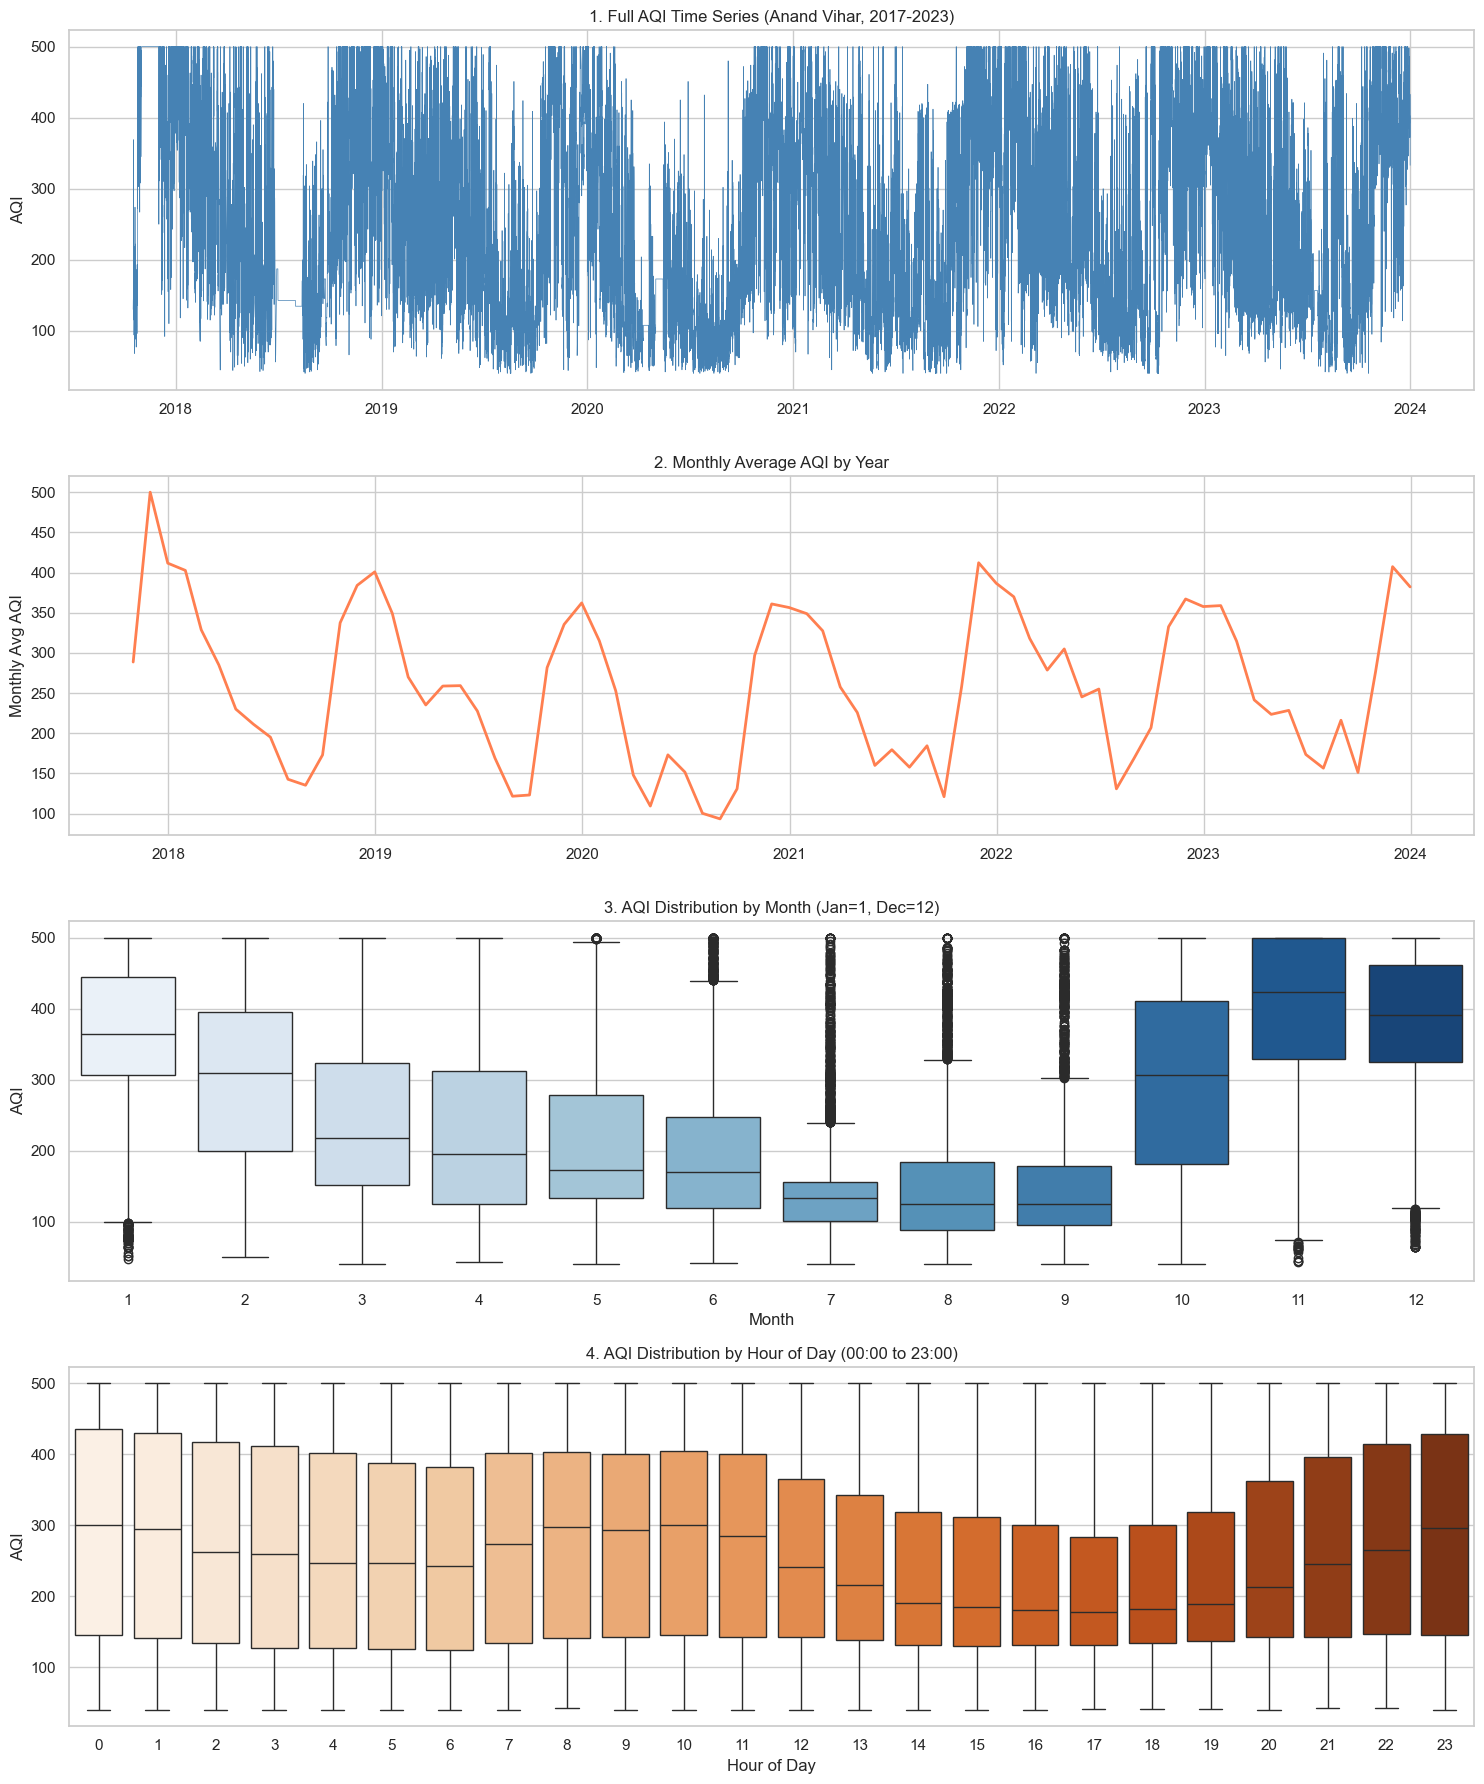

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the clean Stage 0 data
df = pd.read_csv("../Dataset/final_clean_aqi_v3.csv", parse_dates=['Datetime'])
df.set_index('Datetime', inplace=True)

# Quick check: How many hours are stuck at exactly 500? (The scale cap)
cap_count = (df['AQI'] == 500).sum()
print(f"Number of hours with AQI exactly 500: {cap_count}")

# Set a nice visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 1, figsize=(15, 18))

# 1. Full Time Series Plot
axes[0].plot(df.index, df['AQI'], linewidth=0.5, color='steelblue')
axes[0].set_title('1. Full AQI Time Series (Anand Vihar, 2017-2023)')
axes[0].set_ylabel('AQI')

# 2. Monthly Average by Year
monthly_avg = df['AQI'].resample('M').mean()
axes[1].plot(monthly_avg.index, monthly_avg, color='coral', linewidth=2)
axes[1].set_title('2. Monthly Average AQI by Year')
axes[1].set_ylabel('Monthly Avg AQI')

# 3. Average by Month (To see the seasonal U-shape)
sns.boxplot(x=df.index.month, y=df['AQI'], ax=axes[2], palette="Blues")
axes[2].set_title('3. AQI Distribution by Month (Jan=1, Dec=12)')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('AQI')

# 4. Average by Hour of Day
sns.boxplot(x=df.index.hour, y=df['AQI'], ax=axes[3], palette="Oranges")
axes[3].set_title('4. AQI Distribution by Hour of Day (00:00 to 23:00)')
axes[3].set_xlabel('Hour of Day')
axes[3].set_ylabel('AQI')

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../Dataset/final_clean_aqi_v3.csv", parse_dates=["Datetime"])
df["Month"] = df["Datetime"].dt.month
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.dayofweek
df["DayName"] = df["Datetime"].dt.day_name()
df["Is_Weekend"] = np.where(df["DayOfWeek"] >= 5, "Weekend (Sat–Sun)", "Weekday (Mon–Fri)")

# The Indian CPCB AQI scale tops out at 500
ceiling_hours = int((df["AQI"] == 500).sum())
ceiling_pct = (ceiling_hours / len(df)) * 100
print(f"Total continuous hourly records (2017–2023): {len(df)}")
print(f"Hours sitting at the 500 scale ceiling: {ceiling_hours} ({ceiling_pct:.2f}% of dataset)")
print(df["AQI"].describe().round(2))

Total continuous hourly records (2017–2023): 54406
Hours sitting at the 500 scale ceiling: 3820 (7.02% of dataset)
count    54406.00
mean       258.16
std        137.85
min         40.00
25%        137.00
50%        232.00
75%        376.00
max        500.00
Name: AQI, dtype: float64


=== 1. SEASONAL & STUBBLE-BURNING ANALYSIS ===
Oct–Nov (Stubble Burning + Early Inversion) Mean AQI : 347.0
May (Summer Dust / High Mixing Height) Mean AQI      : 212.9
Jul–Sep (Monsoon Wet Deposition) Mean AQI            : 149.1
Oct–Nov increase over May                            : +63.0%


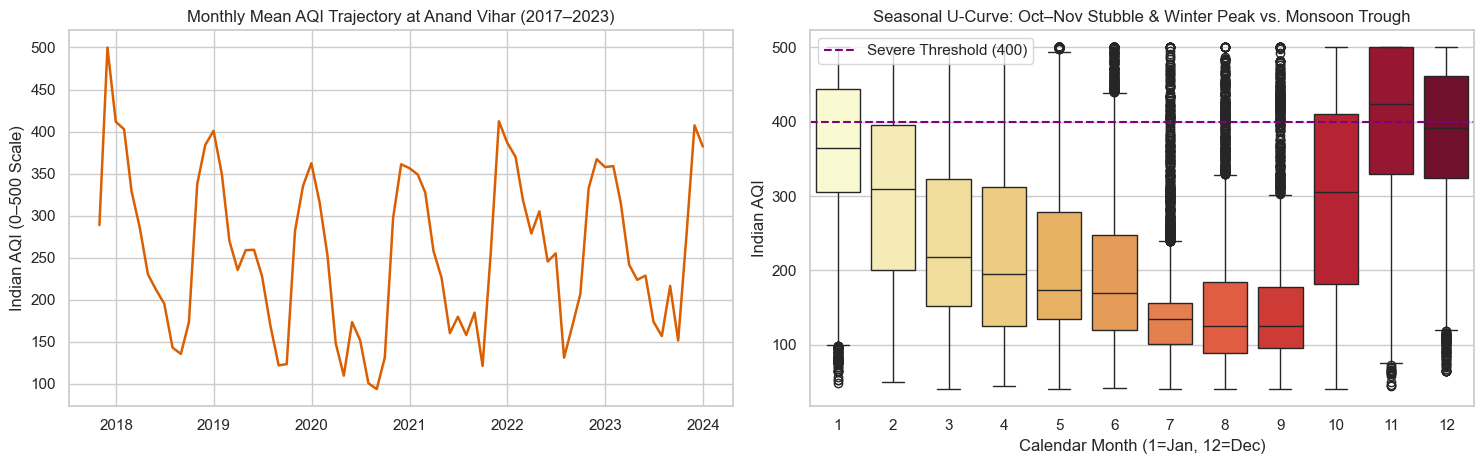

In [2]:
# Compare Post-Monsoon Stubble Burning (Oct-Nov) vs Pre-Monsoon Summer (May) vs Monsoon Washout (Jul-Sep)
oct_nov_mean = df[df["Month"].isin([10, 11])]["AQI"].mean()
may_mean = df[df["Month"] == 5]["AQI"].mean()
monsoon_mean = df[df["Month"].isin([7, 8, 9])]["AQI"].mean()

print("=== 1. SEASONAL & STUBBLE-BURNING ANALYSIS ===")
print(f"Oct–Nov (Stubble Burning + Early Inversion) Mean AQI : {oct_nov_mean:.1f}")
print(f"May (Summer Dust / High Mixing Height) Mean AQI      : {may_mean:.1f}")
print(f"Jul–Sep (Monsoon Wet Deposition) Mean AQI            : {monsoon_mean:.1f}")
print(f"Oct–Nov increase over May                            : +{((oct_nov_mean - may_mean)/may_mean)*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
monthly_series = df.set_index("Datetime")["AQI"].resample("ME").mean()
axes[0].plot(monthly_series.index, monthly_series.values, color="#d95f02", linewidth=1.8)
axes[0].set_title("Monthly Mean AQI Trajectory at Anand Vihar (2017–2023)")
axes[0].set_ylabel("Indian AQI (0–500 Scale)")

sns.boxplot(data=df, x="Month", y="AQI", hue="Month", palette="YlOrRd", legend=False, ax=axes[1])
axes[1].axhline(400, color="purple", linestyle="--", label="Severe Threshold (400)")
axes[1].set_title("Seasonal U-Curve: Oct–Nov Stubble & Winter Peak vs. Monsoon Trough")
axes[1].set_xlabel("Calendar Month (1=Jan, 12=Dec)")
axes[1].set_ylabel("Indian AQI")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.savefig("../Models/eda_seasonal_stubble.png", dpi=300)
plt.show()

=== 2. DIURNAL RUSH-HOUR & MIXING HEIGHT ANALYSIS ===
Morning Rush + Inversion (07:00–10:00) Mean AQI  : 276.1
Afternoon Solar Mixing Dip (14:00–17:00) Mean AQI: 218.0
Night Traffic + Trapping (21:00–01:00) Mean AQI  : 283.7


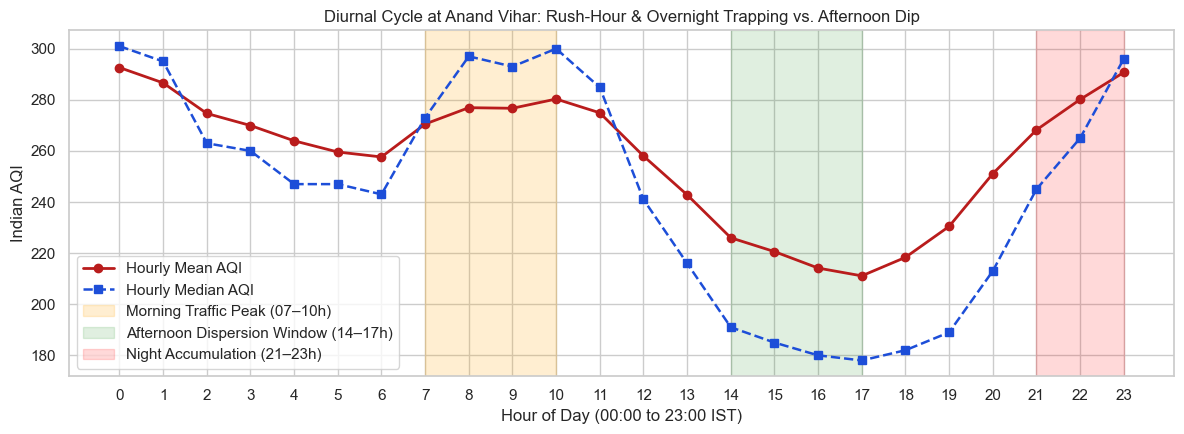

In [3]:
# Compare Morning Peak (07:00-10:00), Afternoon Mixing Dip (14:00-17:00), and Night Peak (21:00-01:00)
morning_rush = df[df["Hour"].isin([7, 8, 9, 10])]["AQI"].mean()
afternoon_dip = df[df["Hour"].isin([14, 15, 16, 17])]["AQI"].mean()
night_accum = df[df["Hour"].isin([21, 22, 23, 0, 1])]["AQI"].mean()

print("=== 2. DIURNAL RUSH-HOUR & MIXING HEIGHT ANALYSIS ===")
print(f"Morning Rush + Inversion (07:00–10:00) Mean AQI  : {morning_rush:.1f}")
print(f"Afternoon Solar Mixing Dip (14:00–17:00) Mean AQI: {afternoon_dip:.1f}")
print(f"Night Traffic + Trapping (21:00–01:00) Mean AQI  : {night_accum:.1f}")

fig, ax = plt.subplots(figsize=(12, 4.5))
hourly_stats = df.groupby("Hour")["AQI"].agg(["mean", "median"])
ax.plot(hourly_stats.index, hourly_stats["mean"], marker="o", color="#b91c1c", linewidth=2, label="Hourly Mean AQI")
ax.plot(hourly_stats.index, hourly_stats["median"], marker="s", color="#1d4ed8", linestyle="--", linewidth=1.8, label="Hourly Median AQI")
ax.axvspan(7, 10, color="orange", alpha=0.18, label="Morning Traffic Peak (07–10h)")
ax.axvspan(14, 17, color="green", alpha=0.12, label="Afternoon Dispersion Window (14–17h)")
ax.axvspan(21, 23, color="red", alpha=0.15, label="Night Accumulation (21–23h)")
ax.set_xticks(range(0, 24))
ax.set_title("Diurnal Cycle at Anand Vihar: Rush-Hour & Overnight Trapping vs. Afternoon Dip")
ax.set_xlabel("Hour of Day (00:00 to 23:00 IST)")
ax.set_ylabel("Indian AQI")
ax.legend()
plt.tight_layout()
plt.savefig("../Models/eda_rush_hour_diurnal.png", dpi=300)
plt.show()

=== 3. WEEKDAY VS. WEEKEND ANALYSIS ===
Weekday (Mon–Fri) Mean AQI : 259.14
Weekend (Sat–Sun) Mean AQI : 255.71 (-1.32% difference)
Finding: Unlike office-only zones, Anand Vihar ISBT & NH-24 experience continuous
7-day inter-state bus and truck movement, so weekend AQI drops by less than 2%.


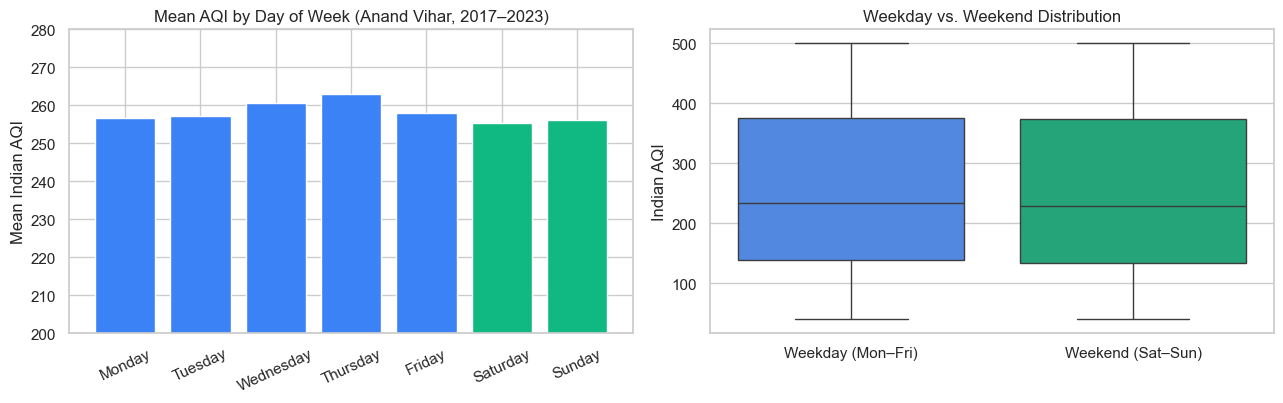

In [4]:
# Check whether weekends show a large drop at Anand Vihar (inter-state bus & highway corridor)
wkday_mean = df[df["DayOfWeek"] < 5]["AQI"].mean()
wkend_mean = df[df["DayOfWeek"] >= 5]["AQI"].mean()
diff_pct = ((wkend_mean - wkday_mean) / wkday_mean) * 100

print("=== 3. WEEKDAY VS. WEEKEND ANALYSIS ===")
print(f"Weekday (Mon–Fri) Mean AQI : {wkday_mean:.2f}")
print(f"Weekend (Sat–Sun) Mean AQI : {wkend_mean:.2f} ({diff_pct:+.2f}% difference)")
print("Finding: Unlike office-only zones, Anand Vihar ISBT & NH-24 experience continuous")
print("7-day inter-state bus and truck movement, so weekend AQI drops by less than 2%.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_means = df.groupby("DayName")["AQI"].mean().reindex(order_days)
axes[0].bar(order_days, day_means.values, color=["#3b82f6"]*5 + ["#10b981"]*2)
axes[0].set_ylim(200, 280)
axes[0].set_title("Mean AQI by Day of Week (Anand Vihar, 2017–2023)")
axes[0].set_ylabel("Mean Indian AQI")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=df, x="Is_Weekend", y="AQI", hue="Is_Weekend", palette=["#3b82f6", "#10b981"], legend=False, ax=axes[1])
axes[1].set_title("Weekday vs. Weekend Distribution")
axes[1].set_xlabel("")
axes[1].set_ylabel("Indian AQI")
plt.tight_layout()
plt.savefig("../Models/eda_weekend_effect.png", dpi=300)
plt.show()